# Fantasy Football: Model Comparison and Evaluation
### CSCI 5502 | Milestone 3

## 1. Objective

The goal of this notebook is to compare the machine learning models developed by our team and evaluate how accurately they predict NFL fantasy football points.

Our main focus is to compare two existing modeling approaches:

1. **Global XGBoost:** A single XGBoost model trained on players across all positions.
2. **Clustered XGBoost:** Three separate XGBoost models trained on position groups identified through clustering:
   - Running Backs (RB)
   - Quarterbacks and Tight Ends (QB + TE)
   - Wide Receivers and Kickers (WR + K)

We will also compare both approaches against ESPN's fantasy point projections as an external benchmark.

## 2. Evaluation Metrics

We will use three regression metrics:

- **Mean Absolute Error (MAE):** Average absolute difference between predicted and actual fantasy points.
- **Root Mean Squared Error (RMSE):** Measures prediction error while penalizing larger mistakes more heavily.
- **R-squared (R²):** Measures how well the predictions explain variation in actual fantasy scores.

## 3. Comparison Strategy

To ensure a fair comparison, we will:

1. Use the same player-game observations for both models.
2. Use chronological training, validation, and testing splits.
3. Check for target leakage and features unavailable before the game.
4. Compare overall prediction performance.
5. Compare model performance across QB, RB, WR, TE, and K.
6. Analyze which model performs better than ESPN and where each model struggles.

The objective is not simply to achieve the lowest error, but to determine which modeling approach is more reliable for predicting future fantasy football performance.


In [1]:

# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# XGBoost
import xgboost as xgb

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
print("XGBoost version:", xgb.__version__)


All libraries imported successfully!
XGBoost version: 3.4.1


In [3]:

# Load datasets from the data folder
data_dir = Path("data")

df_2024 = pd.read_csv(data_dir / "df_2024_final.csv")
df_2025 = pd.read_csv(data_dir / "df_2025_final.csv")
df_2026 = pd.read_csv(data_dir / "df_2026_final.csv")

# Assign season labels
df_2024["season"] = 2024
df_2025["season"] = 2025
df_2026["season"] = 2026

# Combine the datasets
combined = pd.concat(
    [df_2024, df_2025, df_2026],
    ignore_index=True
)

# Check dataset sizes
for year, df in [(2024, df_2024),
                 (2025, df_2025),
                 (2026, df_2026)]:
    print(f"{year}: {df.shape[0]} rows, {df.shape[1]} columns")

print("\nCombined shape:", combined.shape)


2024: 7522 rows, 84 columns
2025: 7572 rows, 84 columns
2026: 4440 rows, 75 columns

Combined shape: (19534, 86)


In [4]:

# Check which columns differ between seasons
cols_2024 = set(df_2024.columns)
cols_2025 = set(df_2025.columns)
cols_2026 = set(df_2026.columns)

print("Columns in 2024 but not 2026:")
print(sorted(cols_2024 - cols_2026))

print("\nColumns in 2026 but not 2024:")
print(sorted(cols_2026 - cols_2024))

# Check important columns for our prediction problem
important_cols = [
    "player_id",
    "player",
    "position",
    "season",
    "week",
    "fantasy_points",
    "projected_points"
]

print("\nImportant columns available:")
for col in important_cols:
    print(f"{col}: {col in combined.columns}")

# Check missing values in important columns
print("\nMissing values by season:")
print(
    combined.groupby("season")[
        important_cols
    ].apply(lambda x: x.isna().sum())
)

# Check sample records
display(combined[important_cols].head())


Columns in 2024 but not 2026:
['assistTackles', 'avgInterceptionYards', 'fumblesRecovered', 'interceptionTouchdowns', 'interceptionYards', 'longInterception', 'passesDefended', 'soloTackles', 'stuffYards', 'stuffs', 'totalTackles']

Columns in 2026 but not 2024:
['pro_team_id', 'season_type']

Important columns available:
player_id: True
player: True
position: True
season: True
week: True
fantasy_points: True
projected_points: True

Missing values by season:
        player_id  player  position  season  week  fantasy_points  \
season                                                              
2024            0       0         0       0     0               0   
2025            0       0         0       0     0               0   
2026            0       0         0       0     0             554   

        projected_points  
season                    
2024                   3  
2025                  30  
2026                 183  


,player_id,player,position,season,week,fantasy_points,projected_points
0,4374302,Amon-Ra St. Brown,WR,2024,18,13.7,18.263253
1,4374302,Amon-Ra St. Brown,WR,2024,17,20.0,17.459376
2,4374302,Amon-Ra St. Brown,WR,2024,16,19.0,17.948622
3,4374302,Amon-Ra St. Brown,WR,2024,15,37.3,17.177120
4,4374302,Amon-Ra St. Brown,WR,2024,14,10.3,17.494361



### Interpretation of Data Inspection

After inspecting the datasets, I found some differences in the columns across seasons. The 2024 dataset contains several defensive statistics that are missing from 2026, while the 2026 dataset includes two additional columns (`pro_team_id` and `season_type`). Since our goal is to compare models fairly, we will need to make sure the models use consistent and relevant features.

All important columns, including player ID, position, season, week, fantasy points, and ESPN projections, are available across the datasets.

I also found that 2024 and 2025 have no missing actual fantasy scores, but 2026 has 554 missing values. ESPN projections are missing for 3 records in 2024, 30 in 2025, and 183 in 2026.

Before evaluating the models, we need to investigate the missing 2026 scores and exclude observations without known outcomes from the evaluation. This will help ensure that our model comparisons are accurate and consistent.



## 5. Investigating Missing Fantasy Scores

The 2026 dataset contains 554 missing fantasy scores. Before preparing the test dataset, we need to investigate which weeks contain these missing values.

We will also check ESPN projection availability and look for duplicate player-week records.

This will help us identify which observations are suitable for evaluating our models.


In [5]:

# Summarize available scores by week
weekly_summary = (
    df_2026.groupby("week")
    .agg(
        total_players=("player_id", "count"),
        actual_scores=("fantasy_points", "count"),
        espn_projections=("projected_points", "count")
    )
)

# Calculate missing scores and projections
weekly_summary["missing_actual"] = (
    weekly_summary["total_players"]
    - weekly_summary["actual_scores"]
)

weekly_summary["missing_espn"] = (
    weekly_summary["total_players"]
    - weekly_summary["espn_projections"]
)

display(weekly_summary)

# Check which weeks contain missing actual scores
print("\nMissing actual scores by week:")
print(
    df_2026[df_2026["fantasy_points"].isna()]
    ["week"].value_counts().sort_index()
)

# Check duplicate player-week observations
duplicates = df_2026.duplicated(
    subset=["player_id", "season", "week"]
).sum()

print("\nDuplicate player-week records:", duplicates)


,total_players,actual_scores,espn_projections,missing_actual,missing_espn
week,,,,,
1,448,448,438,0,10
2,467,467,454,0,13
3,470,470,455,0,15
4,463,463,443,0,20
5,424,424,411,0,13
6,395,395,382,0,13
7,393,393,378,0,15
8,401,401,385,0,16
9,425,425,402,0,23



Missing actual scores by week:
week
10    554
Name: count, dtype: int64

Duplicate player-week records: 0



### Block 5: Interpretation

After examining the 2026 dataset, I found that all 554 missing fantasy scores belong to Week 10. Weeks 1 through 9 have complete actual fantasy scores, which gives us 3,886 player-game observations that can potentially be used for evaluation.

Week 10 contains ESPN projections for 509 players, but none of the actual scores are available. This suggests that the data was collected before those games were completed.

I also checked for duplicate player-season-week records and found none.

Based on these findings, we will use completed games from Weeks 1 through 9 of 2026 as our test period and exclude Week 10 from performance evaluation.

For comparisons with ESPN, we will only use observations where both the actual fantasy score and ESPN projection are available. This ensures a fair comparison across models.

One important detail is that our models predict the next game using historical information. We will therefore need to align each prediction with the correct target game before calculating evaluation metrics.



## 6. Preparing the Modeling Dataset

To compare our models fairly, we first need to construct the prediction target and historical features.

Our target is the fantasy score a player earns in their next scheduled week. We will use previous fantasy scores and rolling averages as historical features, along with known game context.

We will also create chronological training, validation, and testing datasets:

- Training: 2024 and 2025 Weeks 1–9
- Validation: 2025 Weeks 10–18
- Testing: 2026 Weeks 1–9

We will split based on the week being predicted, not the week used to generate the historical features.

To avoid data leakage, the target fantasy score will not be included as an input feature.


In [6]:

# Sort player records chronologically
df_model = combined.sort_values(
    ["player_id", "season", "week"]
).copy()

# Group games by player and season
groups = df_model.groupby(["player_id", "season"])

# Create historical features using current and previous games
df_model["hist_last_score"] = df_model["fantasy_points"]

df_model["hist_last3_avg"] = groups["fantasy_points"].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)

df_model["hist_last5_avg"] = groups["fantasy_points"].transform(
    lambda x: x.rolling(5, min_periods=1).mean()
)

# Create next-game target and known context
df_model["target_points"] = groups["fantasy_points"].shift(-1)
df_model["target_week"] = groups["week"].shift(-1)

df_model["next_opponent"] = groups["opponent"].shift(-1)
df_model["next_atVs"] = groups["atVs"].shift(-1)

# ESPN projection for the game being predicted
df_model["espn_next_projection"] = groups["projected_points"].shift(-1)

# Only retain consecutive-week predictions
# This avoids treating a game after a bye as the immediate next week
df_model = df_model[
    (df_model["target_week"] == df_model["week"] + 1)
    & df_model["target_points"].notna()
].copy()

# Create chronological splits based on the TARGET week
train_data = df_model[
    (df_model["season"] == 2024)
    | (
        (df_model["season"] == 2025)
        & (df_model["target_week"] <= 9)
    )
].copy()

val_data = df_model[
    (df_model["season"] == 2025)
    & (df_model["target_week"] >= 10)
].copy()

test_data = df_model[
    (df_model["season"] == 2026)
    & (df_model["target_week"] <= 9)
].copy()

# Display results
print("Training observations:", len(train_data))
print("Validation observations:", len(val_data))
print("Testing observations:", len(test_data))

print("\nTesting weeks:")
print(sorted(test_data["target_week"].unique()))

print("\nSample modeling records:")
display(
    df_model[
        [
            "player",
            "season",
            "week",
            "hist_last_score",
            "hist_last3_avg",
            "target_week",
            "target_points",
            "espn_next_projection"
        ]
    ].head(10)
)


Training observations: 8831
Validation observations: 3192
Testing observations: 2942

Testing weeks:
[2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]

Sample modeling records:


,player,season,week,hist_last_score,hist_last3_avg,target_week,target_points,espn_next_projection
10886,Philip Rivers,2025,15,6.80,6.800000,16.0,17.08,12.969306
10885,Philip Rivers,2025,16,17.08,11.940000,17.0,7.78,11.352751
2045,Aaron Rodgers,2024,1,8.58,8.580000,2.0,15.14,16.648115
2044,Aaron Rodgers,2024,2,15.14,11.860000,3.0,21.04,15.524362
2043,Aaron Rodgers,2024,3,21.04,14.920000,4.0,11.60,15.447897
2042,Aaron Rodgers,2024,4,11.60,15.926667,5.0,11.76,14.136655
2041,Aaron Rodgers,2024,5,11.76,14.800000,6.0,17.76,14.944102
2040,Aaron Rodgers,2024,6,17.76,13.706667,7.0,13.04,16.106510
2039,Aaron Rodgers,2024,7,13.04,14.186667,8.0,17.32,17.224876
2038,Aaron Rodgers,2024,8,17.32,16.040000,9.0,20.34,13.086940



### Block 6: Interpretation

After preparing the modeling dataset, I obtained 8,831 training observations, 3,192 validation observations, and 2,942 testing observations.

I sorted the data chronologically by player and season, then created historical features using the player's previous fantasy scores. I also shifted the target variable to represent the following week's actual fantasy score.

To avoid incorrectly predicting across missing weeks or bye weeks, I kept only consecutive-week observations. As a result, the 2026 test set covers Weeks 2 through 9.

The sample records confirm that the historical features and target values are aligned correctly. This gives us a consistent dataset for evaluating the global and clustered XGBoost approaches.


In [7]:

# Define the initial features for comparison
numeric_features = [
    "hist_last_score",
    "hist_last3_avg",
    "hist_last5_avg"
]

categorical_features = [
    "position",
    "team",
    "next_opponent",
    "next_atVs"
]

feature_cols = numeric_features + categorical_features

# Create feature matrices
X_train = train_data[feature_cols].copy()
X_val = val_data[feature_cols].copy()
X_test = test_data[feature_cols].copy()

# Create target vectors
y_train = train_data["target_points"]
y_val = val_data["target_points"]
y_test = test_data["target_points"]

# Check missing values
print("Missing training features:")
print(X_train.isna().sum())

print("\nFeature columns:")
print(feature_cols)

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

# Leakage check
assert "target_points" not in feature_cols
assert "espn_next_projection" not in feature_cols

print("\nTarget leakage check passed!")


Missing training features:
hist_last_score    0
hist_last3_avg     0
hist_last5_avg     0
position           0
team               0
next_opponent      0
next_atVs          0
dtype: int64

Feature columns:
['hist_last_score', 'hist_last3_avg', 'hist_last5_avg', 'position', 'team', 'next_opponent', 'next_atVs']

Training shape: (8831, 7)
Validation shape: (3192, 7)
Testing shape: (2942, 7)

Target leakage check passed!



### Block 7: Interpretation

I selected seven features for our initial comparison, including three historical performance features and four categorical features describing the player and upcoming matchup.

The training dataset contains 8,831 observations, the validation dataset contains 3,192, and the testing dataset contains 2,942. All three datasets have the same seven input features.

I also checked for missing values in the training features and found none. The target fantasy score and ESPN projection are excluded from the model inputs to avoid directly revealing the prediction outcome.

Using the same features across models will help us evaluate whether the clustered XGBoost approach performs better than the global XGBoost approach under consistent conditions.


In [8]:

# Convert categorical features to pandas category dtype
# Use categories from all splits to ensure consistent encoding.

for col in categorical_features:
    categories = pd.Index(
        pd.concat([
            X_train[col],
            X_val[col],
            X_test[col]
        ]).dropna().unique()
    )

    for X in [X_train, X_val, X_test]:
        X[col] = pd.Categorical(
            X[col],
            categories=categories
        )

# Verify the feature types
print("Feature data types:")
print(X_train.dtypes)

print("\nCategory consistency check:")
for col in categorical_features:
    consistent = (
        X_train[col].cat.categories.equals(
            X_val[col].cat.categories
        )
        and X_train[col].cat.categories.equals(
            X_test[col].cat.categories
        )
    )
    print(f"{col}: {consistent}")

print("\nAll categorical features prepared!")


Feature data types:
hist_last_score     float64
hist_last3_avg      float64
hist_last5_avg      float64
position           category
team               category
next_opponent      category
next_atVs          category
dtype: object

Category consistency check:
position: True
team: True
next_opponent: True
next_atVs: True

All categorical features prepared!



### Interpretation

I converted the categorical features (position, team, next opponent, and home/away status) into the pandas category data type so that XGBoost can process them correctly.

The three historical performance features remain numerical. I also verified that all categorical features use consistent category definitions across the training, validation, and testing datasets.

All consistency checks passed, so our feature matrices are ready for model training.



## 9. Global XGBoost Model

We first train a single XGBoost regression model using players from all five positions.

This serves as our global modeling approach. Later, we will compare its performance with the clustered XGBoost approach, which trains separate models for different position groups.

We use the validation data for early stopping and reserve the 2026 test data for final evaluation.


In [9]:

# Train one XGBoost model using all player positions
global_model = xgb.XGBRegressor(
    tree_method="hist",
    n_estimators=3000,
    learning_rate=0.005,
    max_depth=5,
    min_child_weight=3,
    subsample=0.7,
    colsample_bytree=0.7,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=12,
    enable_categorical=True,
    early_stopping_rounds=50
)

global_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

# Evaluate on validation data first
val_predictions = global_model.predict(X_val)

global_val_mae = mean_absolute_error(
    y_val, val_predictions
)

global_val_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

global_val_r2 = r2_score(
    y_val, val_predictions
)

print("Global XGBoost Validation Results")
print("----------------------------------")
print("Best iteration:", global_model.best_iteration)
print(f"MAE:  {global_val_mae:.3f}")
print(f"RMSE: {global_val_rmse:.3f}")
print(f"R²:   {global_val_r2:.3f}")


Global XGBoost Validation Results
----------------------------------
Best iteration: 921
MAE:  4.246
RMSE: 5.928
R²:   0.408



### Interpretation

I trained a Global XGBoost model using all five player positions and our seven selected features.

The model achieved a validation MAE of 4.246, RMSE of 5.928, and R² of 0.408. This means the predictions differed from actual fantasy scores by approximately 4.25 points on average.

The best iteration was 921, indicating that early stopping identified this as the best point during training based on validation MAE.

These results will serve as our baseline for comparing the Clustered XGBoost approach. If the clustered models achieve lower errors on the same validation observations, that would provide evidence that separating positions into groups could improve prediction accuracy.



## 10. Preparing Position Clusters

The team's clustering analysis identified three groups based on similarities between player positions:

- Cluster 1: RB
- Cluster 2: QB and TE
- Cluster 3: WR and K

We will use these existing groups to train separate XGBoost models and compare their performance with the Global XGBoost model.

To make the comparison fair, each cluster will use the same seven features and the same chronological training and validation periods.


In [10]:

# Position groups from Tristan's clustering analysis
position_clusters = {
    "RB": ["RB"],
    "QB_TE": ["QB", "TE"],
    "WR_K": ["WR", "K"]
}

# Create separate datasets for each cluster
cluster_data = {}

for cluster_name, positions in position_clusters.items():

    train_mask = train_data["position"].isin(positions)
    val_mask = val_data["position"].isin(positions)
    test_mask = test_data["position"].isin(positions)

    cluster_data[cluster_name] = {
        "X_train": X_train.loc[train_mask],
        "y_train": y_train.loc[train_mask],
        "X_val": X_val.loc[val_mask],
        "y_val": y_val.loc[val_mask],
        "X_test": X_test.loc[test_mask],
        "y_test": y_test.loc[test_mask]
    }

    print(f"\n{cluster_name}")
    print("Training:", train_mask.sum())
    print("Validation:", val_mask.sum())
    print("Testing:", test_mask.sum())

# Check that every observation belongs to one cluster
assert sum(
    len(data["X_train"])
    for data in cluster_data.values()
) == len(X_train)

assert sum(
    len(data["X_val"])
    for data in cluster_data.values()
) == len(X_val)

assert sum(
    len(data["X_test"])
    for data in cluster_data.values()
) == len(X_test)

print("\nAll observations assigned successfully!")



RB
Training: 2129
Validation: 787
Testing: 697

QB_TE
Training: 2771
Validation: 1010
Testing: 973

WR_K
Training: 3931
Validation: 1395
Testing: 1272

All observations assigned successfully!



### Interpretation

I divided the dataset into the three position groups identified in Tristan's clustering analysis: RB, QB + TE, and WR + K.

The WR + K cluster contains the largest number of observations, followed by QB + TE and RB.

I verified that all observations were assigned to exactly one cluster and that the combined training, validation, and testing counts match the Global XGBoost datasets.

This allows us to compare the global and clustered modeling approaches using the same observations and historical feature set.



## 11. Clustered XGBoost Models

In this section, I train three separate XGBoost regression models based on the position groups identified in the team's clustering analysis.

Each model uses the same seven input features and hyperparameter settings as the Global XGBoost model.

I evaluate each cluster using its validation observations, then combine the predictions to calculate an overall validation score.

This will help determine whether separating positions into clusters improves prediction accuracy compared with one shared model.


In [11]:

# Store trained models and validation predictions
cluster_models = {}
cluster_val_predictions = pd.Series(index=y_val.index, dtype=float)

cluster_results = []

for name, data in cluster_data.items():

    model = xgb.XGBRegressor(
        tree_method="hist",
        n_estimators=3000,
        learning_rate=0.005,
        max_depth=5,
        min_child_weight=3,
        subsample=0.7,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=12,
        enable_categorical=True,
        early_stopping_rounds=50
    )

    model.fit(
        data["X_train"],
        data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        verbose=False
    )

    preds = model.predict(data["X_val"])

    # Save predictions using original row indices
    cluster_val_predictions.loc[data["X_val"].index] = preds

    cluster_models[name] = model

    cluster_results.append({
        "Cluster": name,
        "N": len(preds),
        "Best iteration": model.best_iteration,
        "MAE": mean_absolute_error(data["y_val"], preds),
        "RMSE": np.sqrt(mean_squared_error(data["y_val"], preds)),
        "R2": r2_score(data["y_val"], preds)
    })

# Display results for each cluster
cluster_results_df = pd.DataFrame(cluster_results)

display(cluster_results_df.round(3))

# Verify all validation predictions exist
assert cluster_val_predictions.notna().all()

# Calculate overall clustered model performance
cluster_val_mae = mean_absolute_error(
    y_val, cluster_val_predictions.loc[y_val.index]
)

cluster_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        cluster_val_predictions.loc[y_val.index]
    )
)

cluster_val_r2 = r2_score(
    y_val, cluster_val_predictions.loc[y_val.index]
)

print("\nOverall Clustered XGBoost Validation Results")
print("--------------------------------------------")
print(f"MAE:  {cluster_val_mae:.3f}")
print(f"RMSE: {cluster_val_rmse:.3f}")
print(f"R²:   {cluster_val_r2:.3f}")

print("\nGlobal XGBoost Validation MAE:", round(global_val_mae, 3))
print("Clustered XGBoost Validation MAE:", round(cluster_val_mae, 3))


,Cluster,N,Best iteration,MAE,RMSE,R2
0,RB,787,835,4.296,6.208,0.446
1,QB_TE,1010,754,4.138,5.904,0.462
2,WR_K,1395,702,4.416,5.873,0.302



Overall Clustered XGBoost Validation Results
--------------------------------------------
MAE:  4.298
RMSE: 5.967
R²:   0.400

Global XGBoost Validation MAE: 4.246
Clustered XGBoost Validation MAE: 4.298



### Interpretation

I trained three separate XGBoost models using the position clusters identified in our team's earlier analysis.

The RB model achieved an MAE of 4.296, the QB + TE model achieved 4.138, and the WR + K model achieved 4.416. When I combined the predictions across all three clusters, the overall validation MAE was 4.298, with an RMSE of 5.967 and R² of 0.400.

Comparing this with the Global XGBoost model, which achieved an MAE of 4.246, I found that the global approach performed slightly better on the validation dataset. The difference was approximately 0.052 fantasy points in MAE.

This suggests that separating players into these clusters does not necessarily improve prediction accuracy with our current seven-feature setup. However, this is only a validation result, so we need further evaluation before deciding which approach generalizes better.



## 12. Validation Performance by Position

Although the Global XGBoost model achieved a slightly lower overall MAE, this does not tell us whether it performs better for every player position.

In this section, I compare Global XGBoost and Clustered XGBoost separately for QB, RB, WR, TE, and K.

This will help identify which positions benefit from clustering and which positions perform better under a shared global model.


,N,Global_MAE,Clustered_MAE,Cluster_Improvement
position,,,,
K,243,4.251,4.208,0.043
QB,257,6.744,6.760,-0.016
RB,787,4.264,4.296,-0.032
TE,753,3.204,3.243,-0.040
WR,1152,4.358,4.460,-0.102


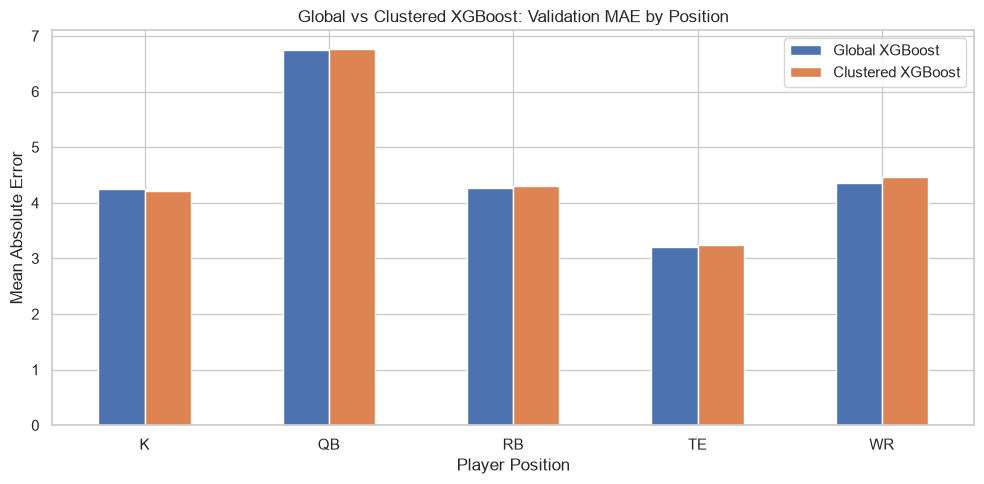

In [12]:

# Prepare a comparison DataFrame for validation observations
position_comparison = val_data[
    ["player", "position", "season", "target_week", "target_points"]
].copy()

# Add predictions from both models
position_comparison["Global_XGB"] = val_predictions
position_comparison["Clustered_XGB"] = (
    cluster_val_predictions.loc[position_comparison.index]
)

# Calculate absolute errors
position_comparison["Global_Error"] = (
    position_comparison["target_points"]
    - position_comparison["Global_XGB"]
).abs()

position_comparison["Clustered_Error"] = (
    position_comparison["target_points"]
    - position_comparison["Clustered_XGB"]
).abs()

# Average prediction error by position
position_results = (
    position_comparison.groupby("position", observed=True)
    .agg(
        N=("target_points", "count"),
        Global_MAE=("Global_Error", "mean"),
        Clustered_MAE=("Clustered_Error", "mean")
    )
)

# Positive improvement means clustering has lower MAE
position_results["Cluster_Improvement"] = (
    position_results["Global_MAE"]
    - position_results["Clustered_MAE"]
)

display(position_results.round(3))

# Plot results
position_results[
    ["Global_MAE", "Clustered_MAE"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Global vs Clustered XGBoost: Validation MAE by Position")
plt.xlabel("Player Position")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.legend(["Global XGBoost", "Clustered XGBoost"])
plt.tight_layout()
plt.show()



### Interpretation

I compared the validation performance of Global XGBoost and Clustered XGBoost across all five player positions.

The results show that Global XGBoost achieved a lower MAE for QB, RB, WR, and TE, while Clustered XGBoost performed slightly better for kickers.

Quarterbacks had the highest prediction errors in both models, while tight ends had the lowest. The largest difference between the models occurred for wide receivers, where clustering increased MAE by approximately 0.102 points.

Overall, the differences between the two approaches were relatively small. Although the clustering analysis identified similarities between player positions, these similarities did not translate into better overall prediction accuracy with our current seven features.

These results suggest that the Global XGBoost model may be more effective for this feature set, but additional evaluation is necessary before drawing conclusions about future performance.



## 13. Comparison with ESPN Projections

In this section, I compare Global XGBoost, Clustered XGBoost, and ESPN's fantasy point projections.

ESPN serves as an external benchmark because its projections are widely used in fantasy football.

To ensure a fair comparison, I will only include validation observations where an ESPN projection and the actual fantasy score are both available.

I will compare all three approaches using MAE, RMSE, and R².


Validation Model Comparison


,Model,N,MAE,RMSE,R2
2,ESPN,3188,3.939,5.661,0.460
0,Global XGBoost,3188,4.251,5.932,0.407
1,Clustered XGBoost,3188,4.303,5.971,0.399


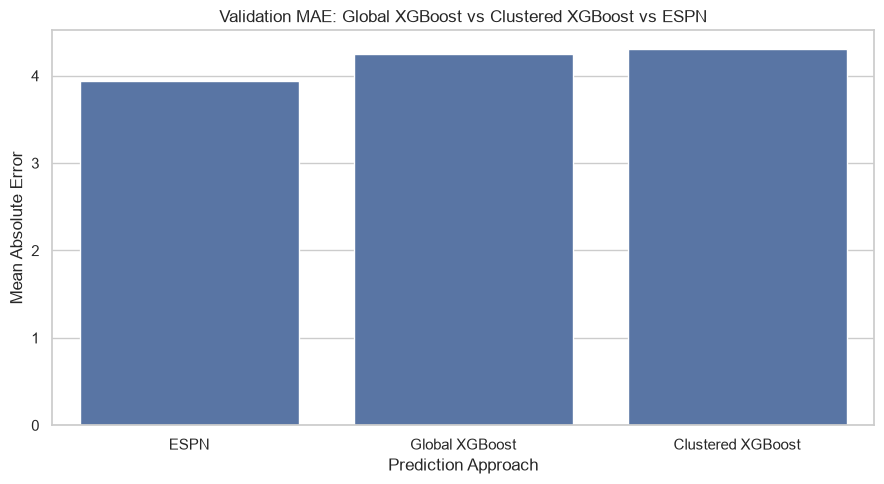

In [13]:

# Create comparison dataset using validation observations
espn_comparison = val_data[
    ["player", "position", "target_points", "espn_next_projection"]
].copy()

# Add predictions from our two models
espn_comparison["Global_XGB"] = val_predictions
espn_comparison["Clustered_XGB"] = (
    cluster_val_predictions.loc[espn_comparison.index]
)

# Keep the same observations for all three approaches
espn_comparison = espn_comparison.dropna(
    subset=[
        "target_points",
        "espn_next_projection",
        "Global_XGB",
        "Clustered_XGB"
    ]
)

# Calculate evaluation metrics
comparison_results = []

models = {
    "Global XGBoost": "Global_XGB",
    "Clustered XGBoost": "Clustered_XGB",
    "ESPN": "espn_next_projection"
}

for name, col in models.items():
    actual = espn_comparison["target_points"]
    predicted = espn_comparison[col]

    comparison_results.append({
        "Model": name,
        "N": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("MAE")

print("Validation Model Comparison")
display(comparison_df.round(3))

# Plot MAE comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="MAE"
)

plt.title("Validation MAE: Global XGBoost vs Clustered XGBoost vs ESPN")
plt.xlabel("Prediction Approach")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()
plt.show()



### Interpretation

I compared Global XGBoost, Clustered XGBoost, and ESPN projections using the same 3,188 validation observations.

ESPN achieved the lowest MAE of 3.939, followed by Global XGBoost at 4.251 and Clustered XGBoost at 4.303. ESPN also had the lowest RMSE and highest R².

Global XGBoost performed slightly better than Clustered XGBoost, with an MAE difference of 0.052 fantasy points. This suggests that separating positions into our three clusters does not improve overall validation accuracy with the current seven-feature setup.

However, both XGBoost models used a limited set of historical and contextual features, while ESPN may incorporate additional information such as injuries, expected playing time, and team conditions.

These findings suggest that feature quality and available information may be important areas for improvement. We will evaluate the models on the separate 2026 test data before drawing final conclusions.



## 14. Individual Prediction Comparison

In this section, I compare the absolute prediction errors for Global XGBoost, Clustered XGBoost, and ESPN on individual player-games.

While MAE summarizes average prediction performance, it does not show how frequently one approach outperforms another.

I will calculate how often each model produces the lowest absolute error, as well as the percentage of predictions where Global and Clustered XGBoost outperform ESPN.


,Count,Percentage
Winner,,
ESPN,1663,52.16
Clustered XGBoost,773,24.25
Global XGBoost,752,23.59


Global XGBoost beats ESPN: 41.5 %
Clustered XGBoost beats ESPN: 40.93 %


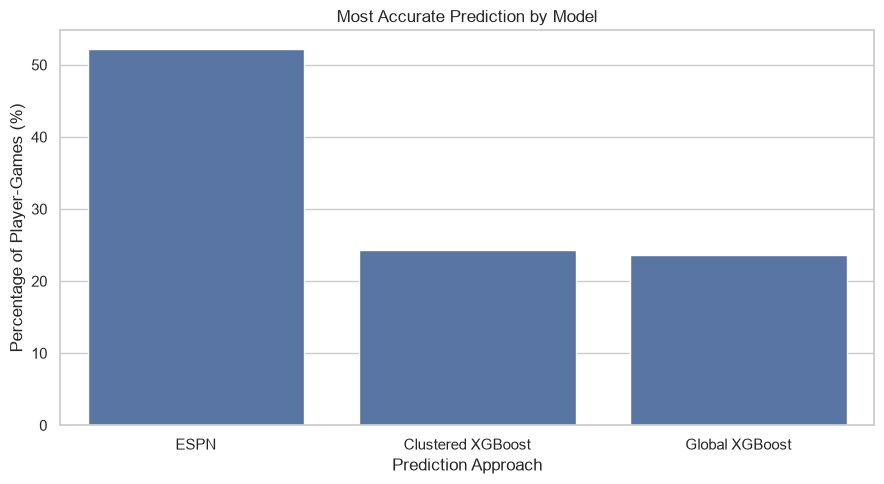

In [14]:

# Use the common validation comparison dataset
error_comparison = espn_comparison.copy()

# Calculate individual absolute errors
error_comparison["Global_Error"] = (
    error_comparison["target_points"]
    - error_comparison["Global_XGB"]
).abs()

error_comparison["Clustered_Error"] = (
    error_comparison["target_points"]
    - error_comparison["Clustered_XGB"]
).abs()

error_comparison["ESPN_Error"] = (
    error_comparison["target_points"]
    - error_comparison["espn_next_projection"]
).abs()

error_cols = [
    "Global_Error",
    "Clustered_Error",
    "ESPN_Error"
]

# Identify which model has the lowest error
# Treat exact ties separately
min_error = error_comparison[error_cols].min(axis=1)

is_winner = error_comparison[error_cols].eq(
    min_error, axis=0
)

error_comparison["Winner"] = np.where(
    is_winner.sum(axis=1) > 1,
    "Tie",
    is_winner.idxmax(axis=1)
)

error_comparison["Winner"] = error_comparison["Winner"].replace({
    "Global_Error": "Global XGBoost",
    "Clustered_Error": "Clustered XGBoost",
    "ESPN_Error": "ESPN"
})

# Number and percentage of wins
winner_counts = error_comparison["Winner"].value_counts()

winner_percent = (
    error_comparison["Winner"]
    .value_counts(normalize=True) * 100
)

winner_summary = pd.DataFrame({
    "Count": winner_counts,
    "Percentage": winner_percent
})

display(winner_summary.round(2))

# Pairwise comparisons against ESPN
print("Global XGBoost beats ESPN:",
      round(
          (error_comparison["Global_Error"]
           < error_comparison["ESPN_Error"]).mean() * 100, 2
      ), "%")

print("Clustered XGBoost beats ESPN:",
      round(
          (error_comparison["Clustered_Error"]
           < error_comparison["ESPN_Error"]).mean() * 100, 2
      ), "%")

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    x=winner_summary.index,
    y=winner_summary["Percentage"]
)

plt.title("Most Accurate Prediction by Model")
plt.xlabel("Prediction Approach")
plt.ylabel("Percentage of Player-Games (%)")
plt.tight_layout()
plt.show()



### Interpretation

I compared the absolute prediction errors of Global XGBoost, Clustered XGBoost, and ESPN across 3,188 validation observations.

ESPN produced the most accurate individual prediction in 52.16% of the games, while Clustered XGBoost won 24.25% and Global XGBoost won 23.59%.

Interestingly, Clustered XGBoost won slightly more individual predictions than Global XGBoost, even though Global XGBoost had a lower overall MAE. This suggests that winning more individual predictions does not necessarily result in a lower average error, since the size of the errors also matters.

In pairwise comparisons against ESPN, Global XGBoost performed better in 41.50% of observations, while Clustered XGBoost performed better in 40.93%.

Overall, ESPN remained the strongest benchmark, but both XGBoost approaches were more accurate for some individual player-games.



## 15. Final Evaluation on 2026 Test Data

After comparing the models on the 2025 validation dataset, I will evaluate Global XGBoost and Clustered XGBoost on the held-out 2026 data.

The models were trained using earlier observations and will not be retrained or tuned using the test set.

I will compare both models with ESPN using the same player-game observations and calculate MAE, RMSE, and R².

This provides a more independent assessment of how well the models generalize to games from a later NFL season.


2026 Test Model Comparison


,Model,N,MAE,RMSE,R2
2,ESPN,2869,3.895,5.510,0.493
0,Global XGBoost,2869,4.334,5.984,0.402
1,Clustered XGBoost,2869,4.371,6.037,0.391


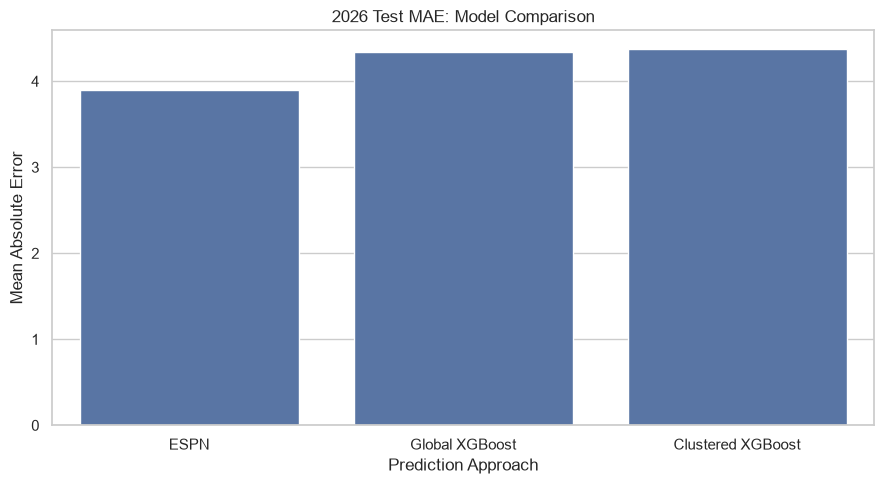

In [15]:

# Global XGBoost predictions on 2026 test data
global_test_predictions = global_model.predict(X_test)

# Clustered XGBoost predictions on 2026 test data
cluster_test_predictions = pd.Series(
    index=X_test.index,
    dtype=float
)

for name, data in cluster_data.items():
    preds = cluster_models[name].predict(data["X_test"])
    cluster_test_predictions.loc[data["X_test"].index] = preds

assert cluster_test_predictions.notna().all()

# Build the common test comparison dataset
test_comparison = test_data[
    ["player", "position", "season",
     "target_week", "target_points",
     "espn_next_projection"]
].copy()

test_comparison["Global_XGB"] = global_test_predictions
test_comparison["Clustered_XGB"] = (
    cluster_test_predictions.loc[test_comparison.index]
)

# Keep observations available for all three approaches
test_comparison = test_comparison.dropna(
    subset=[
        "target_points",
        "espn_next_projection",
        "Global_XGB",
        "Clustered_XGB"
    ]
)

# Evaluate models on identical observations
test_results = []

for name, column in {
    "Global XGBoost": "Global_XGB",
    "Clustered XGBoost": "Clustered_XGB",
    "ESPN": "espn_next_projection"
}.items():

    actual = test_comparison["target_points"]
    predicted = test_comparison[column]

    test_results.append({
        "Model": name,
        "N": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

test_results_df = pd.DataFrame(test_results).sort_values("MAE")

print("2026 Test Model Comparison")
display(test_results_df.round(3))

# Visualize comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=test_results_df,
    x="Model",
    y="MAE"
)

plt.title("2026 Test MAE: Model Comparison")
plt.xlabel("Prediction Approach")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()
plt.show()



### Interpretation

I evaluated Global XGBoost, Clustered XGBoost, and ESPN projections on 2,869 player-game observations from the 2026 test dataset.

ESPN achieved the lowest MAE of 3.895, followed by Global XGBoost at 4.334 and Clustered XGBoost at 4.371. ESPN also achieved the lowest RMSE and highest R².

Global XGBoost performed slightly better than Clustered XGBoost, with an MAE difference of 0.037 fantasy points. This is consistent with the validation results, where the global model also achieved a slightly lower error.

Both XGBoost approaches experienced a small increase in MAE compared with their validation performance, suggesting that prediction performance varies somewhat across seasons.

Overall, the results indicate that position clustering did not improve prediction accuracy compared with the global approach under our current seven-feature setup. However, these findings do not necessarily apply to the team's original models with their larger feature sets.

ESPN remained the strongest benchmark, suggesting that additional predictive information and feature engineering may be needed to improve our models.



## 16. Test Performance by Player Position

In this section, I compare the prediction accuracy of Global XGBoost, Clustered XGBoost, and ESPN across QB, RB, WR, TE, and K.

Although ESPN achieved the best overall results, performance may vary across positions.

I will calculate MAE separately for each position to identify where each modeling approach performs best and where further improvements may be needed.


,N,Global_MAE,Clustered_MAE,ESPN_MAE,Cluster_Improvement
position,,,,,
K,224,3.943,3.886,3.916,0.057
QB,246,6.440,6.572,5.401,-0.131
RB,676,4.209,4.299,3.878,-0.090
TE,684,3.689,3.697,3.101,-0.008
WR,1039,4.424,4.445,4.069,-0.020


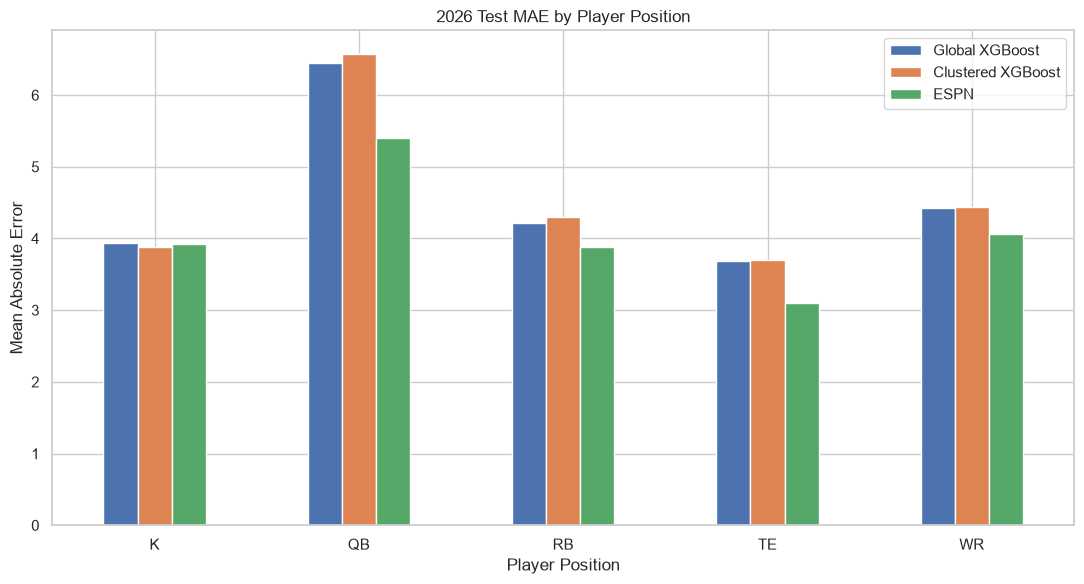

In [16]:

# Compare model errors by position on 2026 test data
position_test = test_comparison.copy()

position_test["Global_Error"] = (
    position_test["target_points"] -
    position_test["Global_XGB"]
).abs()

position_test["Clustered_Error"] = (
    position_test["target_points"] -
    position_test["Clustered_XGB"]
).abs()

position_test["ESPN_Error"] = (
    position_test["target_points"] -
    position_test["espn_next_projection"]
).abs()

# Calculate position-level MAE
position_test_results = (
    position_test.groupby("position")
    .agg(
        N=("target_points", "count"),
        Global_MAE=("Global_Error", "mean"),
        Clustered_MAE=("Clustered_Error", "mean"),
        ESPN_MAE=("ESPN_Error", "mean")
    )
)

# Difference: positive means global performs better than clustered
position_test_results["Cluster_Improvement"] = (
    position_test_results["Global_MAE"] -
    position_test_results["Clustered_MAE"]
)

display(position_test_results.round(3))

# Visualize the results
position_test_results[
    ["Global_MAE", "Clustered_MAE", "ESPN_MAE"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("2026 Test MAE by Player Position")
plt.xlabel("Player Position")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.legend([
    "Global XGBoost",
    "Clustered XGBoost",
    "ESPN"
])
plt.tight_layout()
plt.show()



### Interpretation

I compared the performance of Global XGBoost, Clustered XGBoost, and ESPN across all five player positions using the 2026 test dataset.

The results show that Global XGBoost achieved lower prediction errors than Clustered XGBoost for QB, RB, WR, and TE. However, Clustered XGBoost performed slightly better for kickers, achieving an MAE of 3.886 compared with 3.943 for Global XGBoost.

ESPN achieved the lowest MAE for four of the five positions, with kickers being the only exception.

Quarterbacks had the highest prediction errors across all three approaches, while tight ends had the lowest. This suggests that prediction performance varies by position, although differences in scoring distributions also affect the size of the errors.

Overall, the position-level results support the earlier finding that the Global XGBoost approach performs slightly better than Clustered XGBoost with our current seven-feature setup. The small improvement for kickers suggests that position-specific approaches may still be worth investigating.



## 17. Validation vs. Test Performance

In this section, I compare the validation and test performance of our three prediction approaches.

The validation data comes from late 2025, while the test data comes from Weeks 2–9 of 2026.

The purpose is to examine whether the models maintain similar prediction accuracy when evaluated on a different NFL season.

I will compare MAE across the two periods and calculate how much the error changes.


,Model,MAE_Validation,RMSE_Validation,R2_Validation,MAE_Test,RMSE_Test,R2_Test,MAE_Change
0,ESPN,3.939,5.661,0.460,3.895,5.510,0.493,-0.044
1,Global XGBoost,4.251,5.932,0.407,4.334,5.984,0.402,0.083
2,Clustered XGBoost,4.303,5.971,0.399,4.371,6.037,0.391,0.068


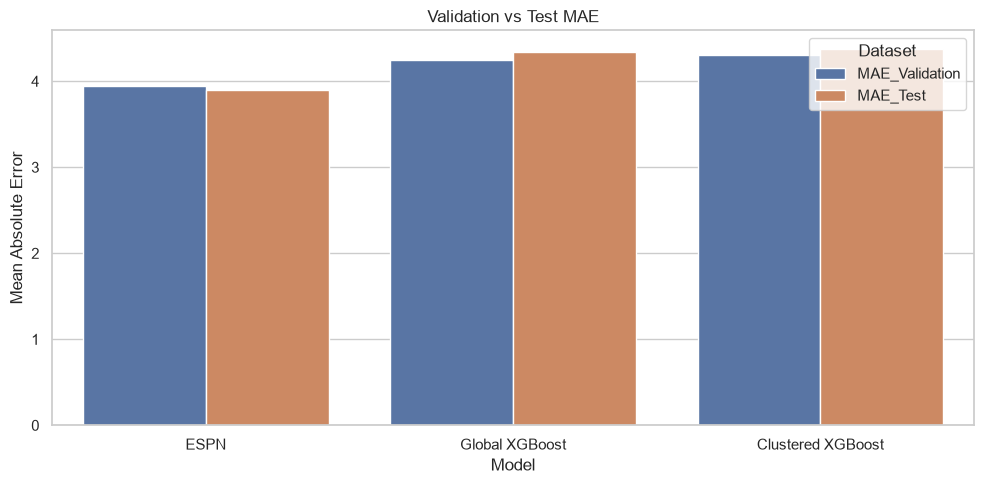

In [17]:

# Combine validation and test results
validation_summary = comparison_df[
    ["Model", "MAE", "RMSE", "R2"]
].copy()

test_summary = test_results_df[
    ["Model", "MAE", "RMSE", "R2"]
].copy()

# Merge based on model name
performance_comparison = validation_summary.merge(
    test_summary,
    on="Model",
    suffixes=("_Validation", "_Test")
)

# Calculate change in MAE
performance_comparison["MAE_Change"] = (
    performance_comparison["MAE_Test"]
    - performance_comparison["MAE_Validation"]
)

display(performance_comparison.round(3))

# Visualize validation vs test MAE
plot_df = performance_comparison.melt(
    id_vars="Model",
    value_vars=["MAE_Validation", "MAE_Test"],
    var_name="Dataset",
    value_name="MAE"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=plot_df,
    x="Model",
    y="MAE",
    hue="Dataset"
)

plt.title("Validation vs Test MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.tight_layout()
plt.show()



### Interpretation

I compared the validation and test performance of Global XGBoost, Clustered XGBoost, and ESPN to examine how consistently each approach performed across seasons.

Global XGBoost's MAE increased from 4.251 on validation to 4.334 on testing, while Clustered XGBoost increased from 4.303 to 4.371. Both models experienced relatively small increases in prediction error.

ESPN's MAE decreased slightly from 3.939 to 3.895 and remained the most accurate approach in both periods.

Global XGBoost also consistently achieved a lower MAE than Clustered XGBoost, although the difference between them was small.

Overall, the results suggest that both XGBoost models maintain reasonably similar prediction performance across the two evaluation periods. However, the differences between seasons mean that these changes cannot be attributed entirely to overfitting or model quality.



## 18. Analysis of Large Prediction Errors

Although the overall performance metrics summarize how well each model predicts fantasy scores, they do not explain which player performances are most difficult to predict.

In this section, I examine the largest prediction errors made by Global XGBoost and compare them with Clustered XGBoost and ESPN.

The goal is to identify whether our models tend to underestimate unusually high-scoring games or overestimate poor performances.


In [18]:

# Copy the 2026 test comparison data
error_analysis = test_comparison.copy()

# Calculate signed errors: actual minus predicted
error_analysis["Global_Signed_Error"] = (
    error_analysis["target_points"]
    - error_analysis["Global_XGB"]
)

error_analysis["Clustered_Signed_Error"] = (
    error_analysis["target_points"]
    - error_analysis["Clustered_XGB"]
)

error_analysis["ESPN_Signed_Error"] = (
    error_analysis["target_points"]
    - error_analysis["espn_next_projection"]
)

# Absolute errors
error_analysis["Global_Abs_Error"] = (
    error_analysis["Global_Signed_Error"].abs()
)

error_analysis["Clustered_Abs_Error"] = (
    error_analysis["Clustered_Signed_Error"].abs()
)

error_analysis["ESPN_Abs_Error"] = (
    error_analysis["ESPN_Signed_Error"].abs()
)

# Show the 10 largest Global XGBoost errors
largest_errors = error_analysis.sort_values(
    "Global_Abs_Error",
    ascending=False
).head(10)

display(
    largest_errors[
        [
            "player",
            "position",
            "target_week",
            "target_points",
            "Global_XGB",
            "Clustered_XGB",
            "espn_next_projection",
            "Global_Signed_Error",
            "Global_Abs_Error"
        ]
    ].round(2)
)

# Compare underprediction and overprediction
for model in [
    "Global",
    "Clustered",
    "ESPN"
]:
    signed = error_analysis[f"{model}_Signed_Error"]

    print(f"\n{model}")
    print("Mean signed error:", round(signed.mean(), 3))
    print(
        "Underprediction rate:",
        round((signed > 0).mean() * 100, 2), "%"
    )
    print(
        "Overprediction rate:",
        round((signed < 0).mean() * 100, 2), "%"
    )


,player,position,target_week,target_points,Global_XGB,Clustered_XGB,espn_next_projection,Global_Signed_Error,Global_Abs_Error
15337,Tetairoa McMillan,WR,4.0,45.20,8.200000,7.27,15.85,37.00,37.00
15639,Davante Adams,WR,2.0,39.50,6.770000,7.63,15.50,32.73,32.73
15134,Jaxon Smith-Njigba,WR,2.0,42.50,14.510000,13.47,18.49,27.99,27.99
15972,Tyler Allgeier,RB,8.0,36.10,8.770000,7.25,7.99,27.33,27.33
15141,CeeDee Lamb,WR,4.0,41.30,14.290000,15.39,16.90,27.01,27.01
15619,Tony Pollard,RB,7.0,36.50,9.670000,8.64,13.81,26.83,26.83
15298,Drake Maye,QB,5.0,39.46,14.840000,16.33,18.47,24.62,24.62
15428,Jaylen Warren,RB,5.0,36.80,13.620000,13.18,17.58,23.18,23.18
16406,Emanuel Wilson,RB,4.0,27.00,4.170000,5.05,11.51,22.83,22.83
15100,Jahmyr Gibbs,RB,3.0,41.40,18.870001,17.83,25.35,22.53,22.53



Global
Mean signed error: -0.105
Underprediction rate: 36.56 %
Overprediction rate: 63.44 %

Clustered
Mean signed error: -0.106
Underprediction rate: 37.12 %
Overprediction rate: 62.88 %

ESPN
Mean signed error: -0.208
Underprediction rate: 35.24 %
Overprediction rate: 58.59 %



### Interpretation

I examined the largest prediction errors made by Global XGBoost on the 2026 test dataset and compared them with Clustered XGBoost and ESPN.

The largest errors came from unusually high-scoring player performances. For example, Tetairoa McMillan scored 45.20 fantasy points, but Global XGBoost predicted only 8.20, resulting in an absolute error of 37 points. Similar underpredictions occurred for Davante Adams, Jaxon Smith-Njigba, and several running backs.

Interestingly, Global XGBoost overpredicted 63.44% of the time and underpredicted 36.56% of the time. Clustered XGBoost showed a similar pattern, with an overprediction rate of 62.88%. Despite this, the largest individual errors were underpredictions of unusually high scores.

The mean signed errors were close to zero for both models, but this does not mean their predictions were accurate because positive and negative errors can cancel each other out.

These findings suggest that our models struggle to capture exceptional player performances. One possible explanation is that our current features focus mainly on historical averages and do not capture sudden changes in playing time, player usage, or team circumstances.

Further feature engineering could help investigate whether additional information improves predictions for these unusual performances.


,N,Global_MAE,Clustered_MAE,ESPN_MAE
Score_Range,,,,
0 or below,801,2.821,2.916,1.771
0–5,735,3.674,3.696,3.690
5–10,551,3.650,3.529,3.794
10–15,366,4.244,4.245,4.349
15–20,195,6.321,6.532,5.630
20–30,184,10.513,10.683,8.928
Above 30,37,20.037,20.262,16.786


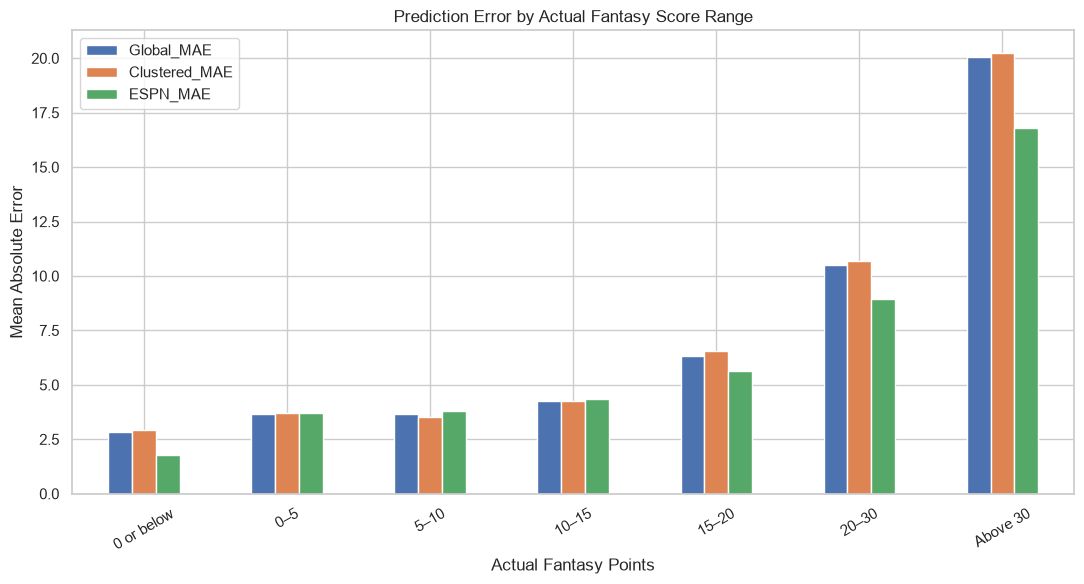

In [19]:

# Group actual fantasy scores into ranges
score_bins = [-np.inf, 0, 5, 10, 15, 20, 30, np.inf]

score_labels = [
    "0 or below",
    "0–5",
    "5–10",
    "10–15",
    "15–20",
    "20–30",
    "Above 30"
]

error_analysis["Score_Range"] = pd.cut(
    error_analysis["target_points"],
    bins=score_bins,
    labels=score_labels
)

# Calculate average absolute error for each range
score_range_results = (
    error_analysis.groupby("Score_Range", observed=True)
    .agg(
        N=("target_points", "count"),
        Global_MAE=("Global_Abs_Error", "mean"),
        Clustered_MAE=("Clustered_Abs_Error", "mean"),
        ESPN_MAE=("ESPN_Abs_Error", "mean")
    )
)

display(score_range_results.round(3))

# Visualize performance
score_range_results[
    ["Global_MAE", "Clustered_MAE", "ESPN_MAE"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Prediction Error by Actual Fantasy Score Range")
plt.xlabel("Actual Fantasy Points")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



### Interpretation

I grouped the 2026 test observations by their actual fantasy scores to investigate how prediction accuracy changes across scoring ranges.

The results show that all three approaches have substantially higher prediction errors for unusually high-scoring performances. For games where players scored above 30 fantasy points, Global XGBoost achieved an MAE of 20.037, Clustered XGBoost achieved 20.262, and ESPN achieved 16.786.

Both XGBoost models were competitive with ESPN in several lower and moderate scoring ranges, particularly between 0 and 15 points. However, ESPN performed noticeably better for zero or negative scores and for scores above 15 points.

One interesting observation is that the largest prediction errors occur in a relatively small number of high-scoring games. Only 37 observations had actual scores above 30 points, but the errors in this category were substantially higher.

Overall, these findings suggest that our models tend to predict typical performances more accurately than exceptional performances. The current feature set may not contain enough information to anticipate sudden increases in player performance.

This analysis also helps explain why ESPN achieved a lower overall MAE despite our XGBoost models performing competitively in some scoring ranges.



## 20. Model Comparison: Summary and Conclusion

### Summary of Findings

The purpose of this analysis was to compare the Global XGBoost and Clustered XGBoost approaches developed by our team, using ESPN projections as an external benchmark.

I trained both modeling approaches using the same seven features and chronological data splits, then evaluated their performance on 2025 validation data and 2026 test data.

The final 2026 test results were:

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| ESPN | 3.895 | 5.510 | 0.493 |
| Global XGBoost | 4.334 | 5.984 | 0.402 |
| Clustered XGBoost | 4.371 | 6.037 | 0.391 |

### Model Selection

Based on our controlled comparison, Global XGBoost is the preferred approach among the two XGBoost strategies.

Although the team's clustering analysis identified similarities between positions, training separate models for RB, QB + TE, and WR + K did not improve overall prediction accuracy.

Global XGBoost achieved a slightly lower MAE on both validation and testing data. However, the difference between the two approaches was small, so the results do not establish that clustering is always less effective.

### Error Analysis

The models performed reasonably well for many typical player performances but struggled with unusually high fantasy scores.

Prediction errors increased substantially for players scoring above 20 points, especially those exceeding 30 fantasy points.

ESPN generally performed better on unusually low and high scoring games, which contributed to its stronger overall accuracy.

### Limitations

This comparison used seven shared features rather than reproducing the complete feature sets from the team's original XGBoost notebooks.

The 2026 test evaluation included consecutive-week predictions from Weeks 2–9, excluding players without a previous-week observation.

ESPN may also use additional information not available in our current dataset.

### Conclusion

The results suggest that separating player positions into clusters does not automatically improve predictive performance.

For our current feature set, the Global XGBoost approach provides slightly better accuracy with a simpler modeling structure.

Future work could include additional historical performance statistics, player usage trends, injury information, and position-specific features to investigate whether these improvements help reduce prediction errors.
